# Tugas 2 - Klasifikasi Diabetes dengan Naive Bayes dan Logistic Regression

| Nama | NRP |
|------|-----|
| Ahmad Zaki Fauzan Nabil | 5054251044 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Pima Indians Diabetes Dataset. Dataset bisa diakses melalui link berikut:
https://www.kaggle.com/datasets/jamaltariqcheema/pima-indians-diabetes-dataset

Tujuan utama dari tugas ini adalah membangun model Naive Bayes dan Logistic Regression untuk mengklasifikasikan apakah seorang pasien menderita diabetes atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Gaussian Naive Bayes dan Logistic Regression.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil kedua model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
file_path = "diabetes.csv" if os.path.exists("diabetes.csv") else "diabetes(1).csv"
df = pd.read_csv(file_path)

print(f"Dimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
print("Informasi tipe data dan memori:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe())

print("Jumlah missing value standar (NaN):")
print(df.isnull().sum())

Dimensi dataset: 768 baris, 9 kolom

Informasi tipe data dan memori:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB

Statistik deskriptif:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Jumlah missing value standar (NaN):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Frekuensi kelas target:
Outcome
0    500
1    268
Name: count, dtype: int64

Persentase per kelas (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


C:\Users\ahmad\AppData\Local\Temp\ipykernel_16856\120659879.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Outcome', data=df, palette='Set2')


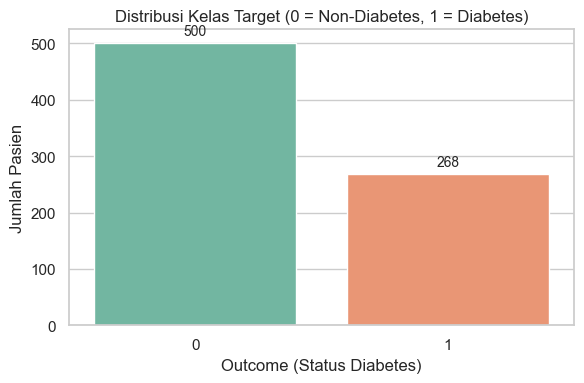

In [3]:
# Tampilkan distribusi kelas target (Outcome) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
print("Frekuensi kelas target:")
print(df['Outcome'].value_counts())
print("\nPersentase per kelas (%):")
print((df['Outcome'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Outcome', data=df, palette='Set2')
plt.title("Distribusi Kelas Target (0 = Non-Diabetes, 1 = Diabetes)")
plt.xlabel("Outcome (Status Diabetes)")
plt.ylabel("Jumlah Pasien")

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, 
                xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

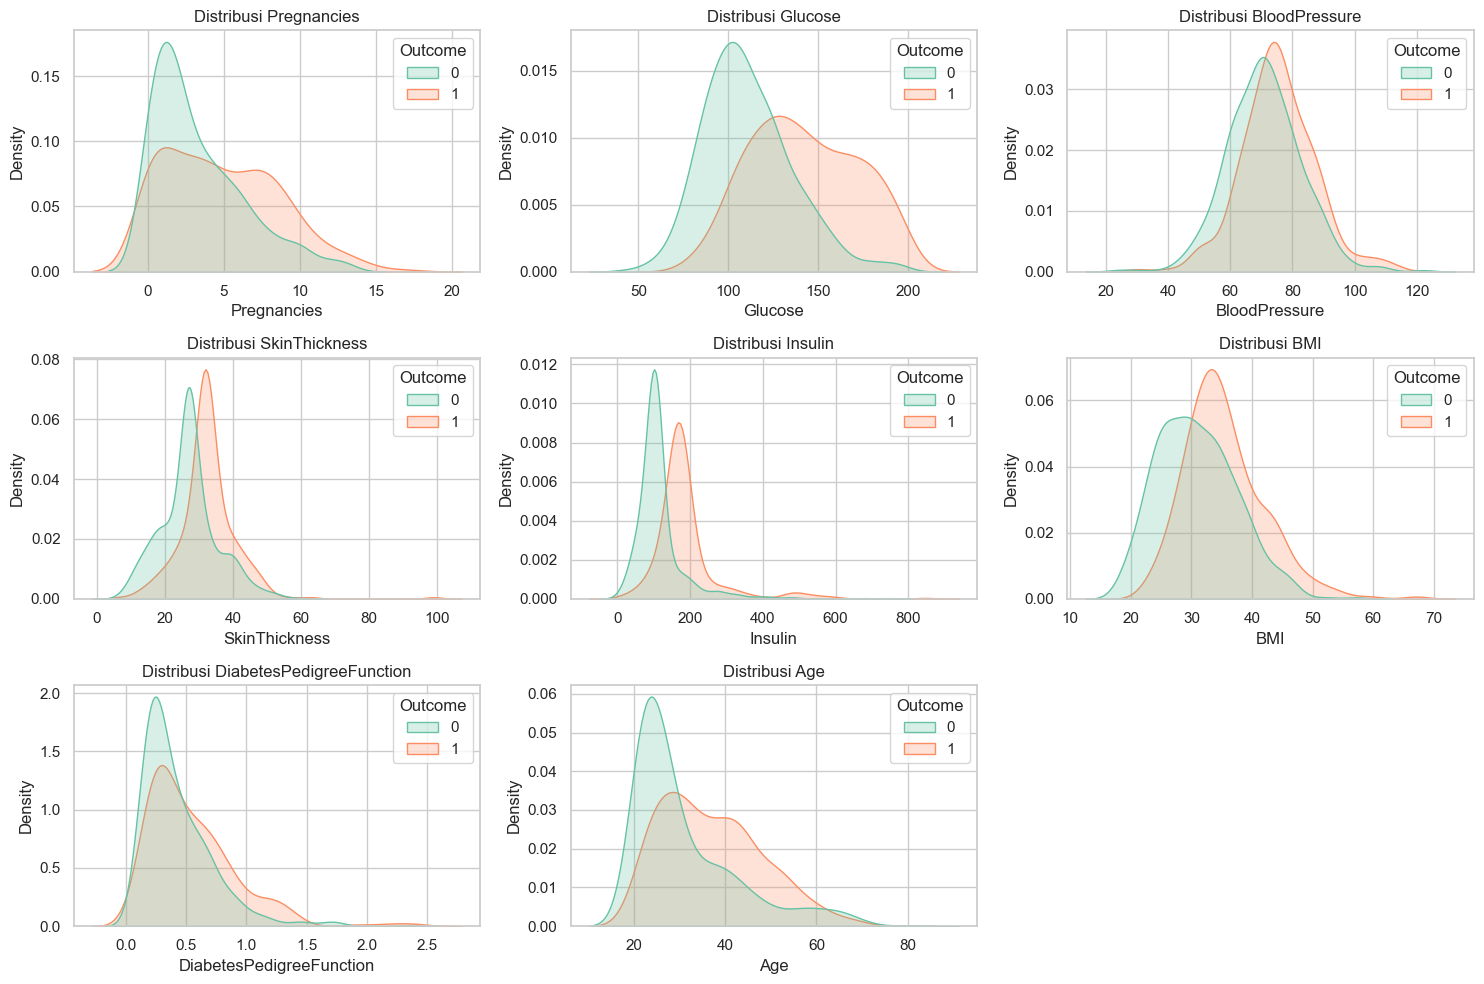

In [4]:
# Tampilkan distribusi setiap fitur menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Outcome.
features = [col for col in df.columns if col != 'Outcome']

plt.figure(figsize=(15, 10))
for i, col in enumerate(features, 1):
    plt.subplot(3, 3, i)
    sns.kdeplot(data=df, x=col, hue='Outcome', common_norm=False, fill=True, palette='Set2')
    plt.title(f"Distribusi {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

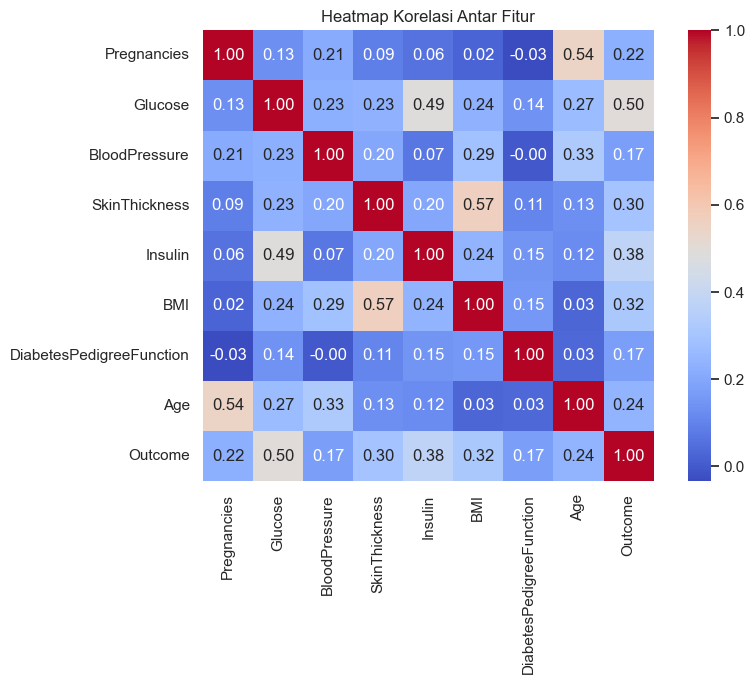

In [5]:
# Tampilkan heatmap korelasi antar fitur.
plt.figure(figsize=(9, 7))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Heatmap Korelasi Antar Fitur")
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

C:\Users\ahmad\AppData\Local\Temp\ipykernel_16856\2123347653.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y=col, data=df, palette='Set2')
C:\Users\ahmad\AppData\Local\Temp\ipykernel_16856\2123347653.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y=col, data=df, palette='Set2')
C:\Users\ahmad\AppData\Local\Temp\ipykernel_16856\2123347653.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Outcome', y=col, data=df, palette='Set2')
C:\Users\ahmad\AppData\Local\Temp\ipykernel_16856\2123347653.py:7: Future

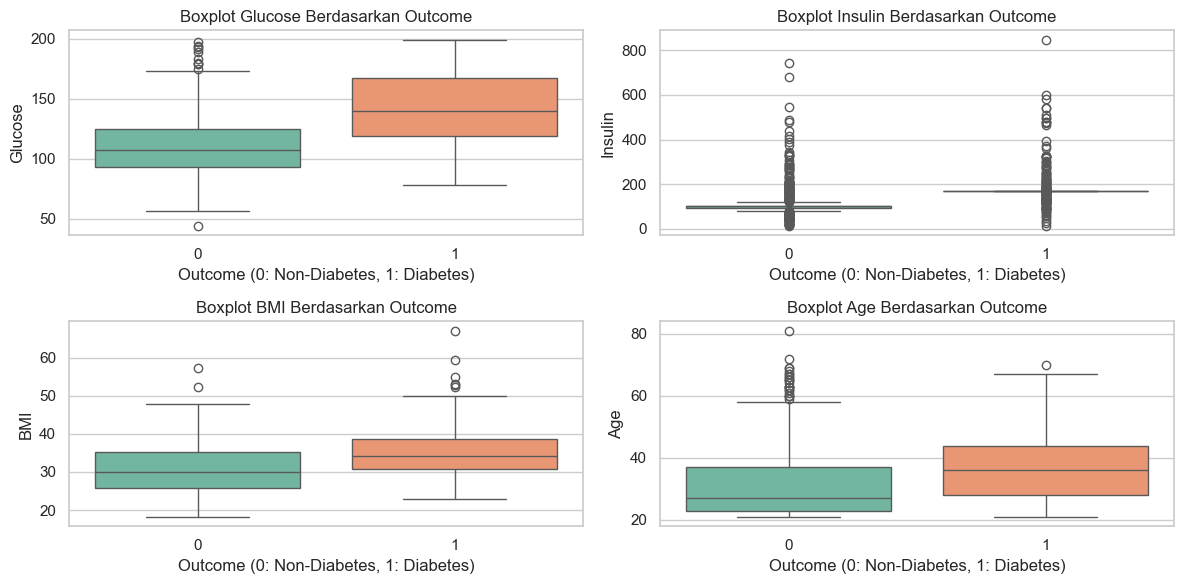

In [6]:
# EDA tambahan: Boxplot sebaran fitur utama terhadap kelas Outcome untuk melihat perbedaan nilai tengah dan sebaran data
key_features = ['Glucose', 'Insulin', 'BMI', 'Age']

plt.figure(figsize=(12, 6))
for i, col in enumerate(key_features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x='Outcome', y=col, data=df, palette='Set2')
    plt.title(f"Boxplot {col} Berdasarkan Outcome")
    plt.xlabel("Outcome (0: Non-Diabetes, 1: Diabetes)")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

# 2. Preprocessing

In [7]:
# Beberapa kolom seperti Glucose, BloodPressure, SkinThickness, Insulin, dan BMI memiliki nilai 0 yang secara medis tidak mungkin.
# Identifikasi kolom-kolom tersebut dan hitung jumlah nilai 0 pada masing-masing kolom.
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Jumlah nilai 0 pada masing-masing kolom fisiologis:")
for col in zero_cols:
    count_0 = (df[col] == 0).sum()
    pct_0 = (count_0 / len(df)) * 100
    print(f"- {col:15s}: {count_0} nilai 0 ({pct_0:.2f}%)")

Jumlah nilai 0 pada masing-masing kolom fisiologis:
- Glucose        : 0 nilai 0 (0.00%)
- BloodPressure  : 0 nilai 0 (0.00%)
- SkinThickness  : 0 nilai 0 (0.00%)
- Insulin        : 0 nilai 0 (0.00%)
- BMI            : 0 nilai 0 (0.00%)


In [8]:
# Tangani nilai 0 tersebut dengan strategi yang sesuai (misalnya imputasi dengan median atau mean).
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

# Mengganti nilai 0 pada kolom fisiologis dengan NaN jika ditemukan
df[zero_cols] = df[zero_cols].replace(0, np.nan)

# Menyiapkan strategi imputasi dengan median.
# Untuk mencegah data leakage, perhitungan median tidak dilakukan pada seluruh dataset,
# melainkan objek imputer disiapkan dan akan di-fit HANYA pada data training setelah split.
imputer = SimpleImputer(strategy='median')

print("Jumlah NaN pada kolom fisiologis (siap diimputasi setelah split):")
print(df[zero_cols].isnull().sum())

Jumlah NaN pada kolom fisiologis (siap diimputasi setelah split):
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [9]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Imputasi nilai: fit pada X_train, kemudian transform pada X_train dan X_test (mencegah data leakage)
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

print(f"Dimensi X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Dimensi y_train: {y_train.shape}, y_test: {y_test.shape}")
print("\nProporsi kelas target pada train set:")
print(y_train.value_counts(normalize=True).round(4))
print("\nProporsi kelas target pada test set:")
print(y_test.value_counts(normalize=True).round(4))

Dimensi X_train: (614, 8), X_test: (154, 8)
Dimensi y_train: (614,), y_test: (154,)

Proporsi kelas target pada train set:
Outcome
0    0.6515
1    0.3485
Name: proportion, dtype: float64

Proporsi kelas target pada test set:
Outcome
0    0.6494
1    0.3506
Name: proportion, dtype: float64


In [10]:
# Lakukan feature scaling menggunakan StandardScaler.
# Fit hanya pada train set, kemudian transform pada train set dan test set.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Contoh data setelah standarisasi (3 baris pertama X_train):")
print(np.round(X_train_scaled[:3], 4))

Contoh data setelah standarisasi (3 baris pertama X_train):
[[-0.8514 -1.0569 -0.8267 -1.8953 -1.1704 -0.7662  0.3108 -0.7922]
 [ 0.3566  0.1429  0.477  -0.2247 -1.4276 -0.4144 -0.1164  0.561 ]
 [-0.5494 -0.557  -1.1526  1.2231 -0.5456  0.3622 -0.7649 -0.7076]]


# 3. Eksperimen Model

## 3.1 Gaussian Naive Bayes

Gunakan GaussianNB karena semua fitur pada dataset ini bersifat numerik kontinu.

In [11]:
# Inisialisasi dan latih model Gaussian Naive Bayes menggunakan train set.
model_gnb = GaussianNB()
model_gnb.fit(X_train_scaled, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[400.,214.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.65,0.35]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[-0.15,-0.38,-0.14,...,-0.24,-0.12,-0.18], [ 0.28, 0.71, 0.26,..., 0.45, 0.23, 0.33]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[0.81,0.61,0.98,...,0.86,0.85,0.96], [1.23,0.97,0.94,...,0.94,1.2 ,0.91]]"


In [12]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_gnb = model_gnb.predict(X_test_scaled)
y_prob_gnb = model_gnb.predict_proba(X_test_scaled)[:, 1]

print("Contoh 5 hasil prediksi label (Gaussian NB):", y_pred_gnb[:5])
print("Contoh 5 hasil probabilitas kelas 1:", np.round(y_prob_gnb[:5], 4))

Contoh 5 hasil prediksi label (Gaussian NB): [0 0 0 0 0]
Contoh 5 hasil probabilitas kelas 1: [0.3946 0.2109 0.2328 0.1853 0.0061]


## 3.2 Logistic Regression

In [13]:
# Inisialisasi dan latih model Logistic Regression menggunakan train set.
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

In [14]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_lr = model_lr.predict(X_test_scaled)
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

print("Contoh 5 hasil prediksi label (Logistic Regression):", y_pred_lr[:5])
print("Contoh 5 hasil probabilitas kelas 1:", np.round(y_prob_lr[:5], 4))

Contoh 5 hasil prediksi label (Logistic Regression): [0 0 0 0 0]
Contoh 5 hasil probabilitas kelas 1: [0.4774 0.0741 0.3701 0.3377 0.032 ]


# 4. Evaluasi Model

In [15]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
eval_summary = {
    "Model": ["Gaussian Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_gnb),
        accuracy_score(y_test, y_pred_lr)
    ],
    "Precision": [
        precision_score(y_test, y_pred_gnb),
        precision_score(y_test, y_pred_lr)
    ],
    "Recall": [
        recall_score(y_test, y_pred_gnb),
        recall_score(y_test, y_pred_lr)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_gnb),
        f1_score(y_test, y_pred_lr)
    ],
    "ROC AUC": [
        roc_auc_score(y_test, y_prob_gnb),
        roc_auc_score(y_test, y_prob_lr)
    ]
}

df_eval = pd.DataFrame(eval_summary)
df_eval.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC AUC
0,Gaussian Naive Bayes,0.7273,0.6034,0.6481,0.6250,0.8017
1,Logistic Regression,0.7078,0.5882,0.5556,0.5714,0.8263


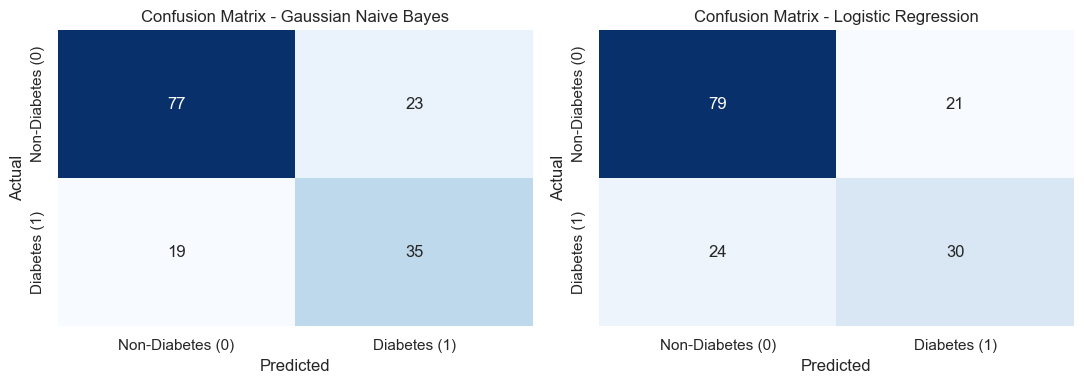

In [16]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

models_cm = [
    ("Gaussian Naive Bayes", y_pred_gnb),
    ("Logistic Regression", y_pred_lr)
]

for ax, (name, y_pred) in zip(axes, models_cm):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Non-Diabetes (0)', 'Diabetes (1)'],
                yticklabels=['Non-Diabetes (0)', 'Diabetes (1)'])
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

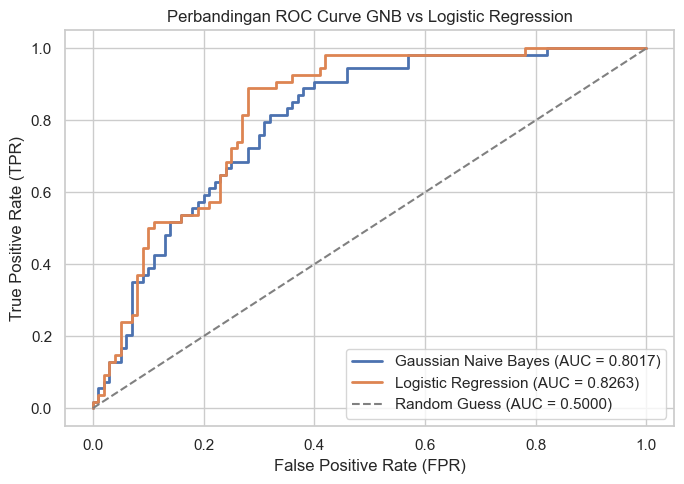

In [17]:
# Tampilkan ROC Curve kedua model dalam satu plot beserta nilai AUC masing-masing.
plt.figure(figsize=(7, 5))

models_roc = [
    ("Gaussian Naive Bayes", y_prob_gnb),
    ("Logistic Regression", y_prob_lr)
]

for name, y_prob in models_roc:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], color='grey', linestyle='--', label="Random Guess (AUC = 0.5000)")
plt.title("Perbandingan ROC Curve GNB vs Logistic Regression")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

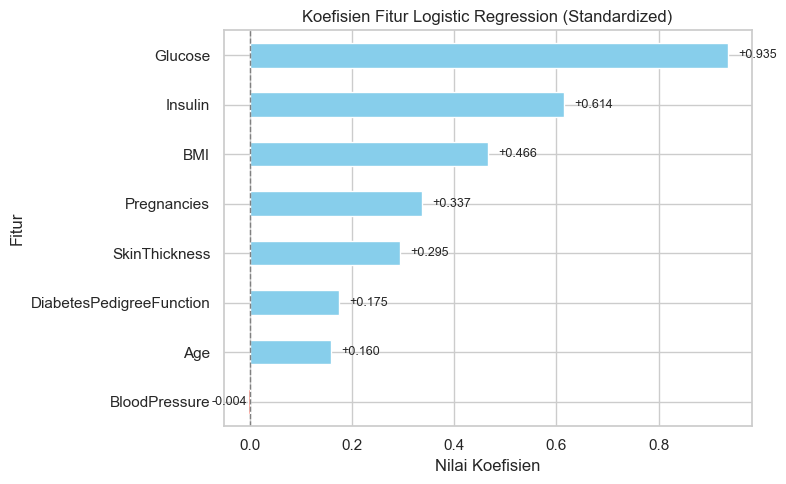

In [18]:
# Khusus Logistic Regression: tampilkan koefisien setiap fitur dalam bentuk bar chart horizontal.
# Koefisien positif menandakan fitur meningkatkan probabilitas diabetes, negatif sebaliknya.
coefficients = pd.Series(model_lr.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
colors = ['salmon' if val < 0 else 'skyblue' for val in coefficients]
coefficients.plot(kind='barh', color=colors)
plt.axvline(x=0, color='grey', linestyle='--', linewidth=1)
plt.title("Koefisien Fitur Logistic Regression (Standardized)")
plt.xlabel("Nilai Koefisien")
plt.ylabel("Fitur")

for i, val in enumerate(coefficients):
    plt.text(val + (0.02 if val >= 0 else -0.07), i, f"{val:+.3f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Gaussian Naive Bayes dan Logistic Regression berdasarkan hasil evaluasi. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

---

### Pembahasan Hasil Eksperimen

Berdasarkan pengujian pada dataset Pima Indians Diabetes (154 sampel data uji dengan pembagian 80:20 berstrata), berikut adalah analisis mendalam terhadap perbandingan performa Gaussian Naive Bayes dan Logistic Regression:

#### 1. Perbandingan Kinerja Model
| Metrik Evaluasi | Gaussian Naive Bayes | Logistic Regression |
|---|:---:|:---:|
| **Accuracy** | **0.7273 (72.73%)** | 0.7078 (70.78%) |
| **Precision** | **0.6034 (60.34%)** | 0.5882 (58.82%) |
| **Recall** | **0.6481 (64.81%)** | 0.5556 (55.56%) |
| **F1-Score** | **0.6250 (62.50%)** | 0.5714 (57.14%) |
| **ROC AUC** | 0.8017 | **0.8263** |

- **Akurasi & Sensitivitas (Recall):** Pada threshold keputusan bawaan (0.5), Gaussian Naive Bayes memperoleh akurasi sedikit lebih tinggi (72.73% vs 70.78%) serta tingkat Recall yang lebih unggul (64.81% vs 55.56%). Hal ini mengindikasikan bahwa Gaussian Naive Bayes mampu mengidentifikasi lebih banyak pasien diabetes sebenarnya (35 pasien) dibandingkan Logistic Regression (30 pasien).
- **Kemampuan Diskriminasi Probabilitas (ROC AUC):** Meskipun akurasinya sedikit lebih rendah pada threshold 0.5, **Logistic Regression menghasilkan nilai ROC-AUC yang lebih unggul (0.8263 vs 0.8017)**. Kurva ROC menunjukkan bahwa Logistic Regression memiliki perankingan probabilitas yang lebih baik secara konsisten di berbagai variasi threshold.

---

#### 2. Kaitan Performa dengan Karakteristik Model

1. **Gaussian Naive Bayes (Pendekatan Generatif)**
   - *Mekanisme:* GNB memodelkan distribusi data pada masing-masing kelas dengan asumsi bahwa setiap fitur kontinu berdistribusi Gaussian (Normal) dan saling independen secara kondisional ($P(X \mid Y) = \prod P(X_i \mid Y)$).
   - *Kelemahan & Kelebihan:* Pada kenyataannya, fitur-fitur medis saling berkaitan—misalnya `Age` berkorelasi positif dengan `Pregnancies` (r = 0.54) dan `Glucose` berkorelasi dengan `Insulin` (r = 0.40). Beberapa fitur seperti `Insulin` juga memiliki sebaran yang menceng (*right-skewed*). Walaupun asumsi independensi dan normalitas terlanggar sebagian, GNB tetap mampu menangkap pemisahan kelas secara generatif dan menghasilkan tingkat Recall yang kompetitif.

2. **Logistic Regression (Pendekatan Diskriminatif)**
   - *Mekanisme:* Memodelkan log-odds probabilitas kelas secara langsung melalui kombinasi linear berbobot: $\log\left(
rac{p}{1-p}
ight) = eta_0 + \sum eta_i X_i$.
   - *Kelebihan:* Model ini tidak mengasumsikan normalitas distribusi maupun independensi antar fitur. Dengan bantuan `StandardScaler`, penalti regularisasi bekerja seimbang di semua fitur, menghasilkan estimasi probabilitas yang halus dan terkalibrasi dengan baik (tercermin pada nilai AUC 0.8263).

---

#### 3. Analisis Koefisien Fitur Logistic Regression
Dari visualisasi koefisien terstandarisasi:
- **Glucose (+0.935)**: Merupakan prediktor dengan kontribusi positif paling dominan. Semakin tinggi kadar glukosa darah puasa, semakin tinggi risiko seorang pasien mengidap diabetes.
- **Insulin (+0.614)** dan **BMI (+0.466)**: Bertindak sebagai faktor risiko signifikan berikutnya, yang sangat selaras dengan pengetahuan medis bahwa resistensi insulin dan indeks massa tubuh yang tinggi (obesitas) adalah pemicu utama diabetes tipe 2.
- **Pregnancies (+0.337)**, **SkinThickness (+0.295)**, **DiabetesPedigreeFunction (+0.175)**, dan **Age (+0.160)**: Memiliki koefisien positif moderat yang turut meningkatkan kemungkinan risiko.
- **BloodPressure (-0.004)**: Memiliki bobot mendekati nol, menunjukkan bahwa setelah dikontrol oleh variabel klinis lain, tekanan darah diastolik memiliki pengaruh marjinal yang sangat minim terhadap diagnosis diabetes pada dataset ini.

---

#### 4. Analisis Confusion Matrix & Relevansi Medis
- **Gaussian Naive Bayes**: True Negative = 77, False Positive = 23, False Negative = 19, True Positive = 35.
- **Logistic Regression**: True Negative = 79, False Positive = 21, False Negative = 24, True Positive = 30.

Dalam konteks medis, **False Negative (pasien diabetes yang tidak terdeteksi) berpotensi berakibat fatal** karena menunda penanganan yang dibutuhkan. Gaussian Naive Bayes memberikan False Negative yang lebih rendah (19 vs 24). Namun, karena Logistic Regression memiliki ROC-AUC yang lebih tinggi (0.8263), jika decision threshold Logistic Regression diturunkan sedikit (misalnya menjadi 0.35 atau 0.40), model dapat mencapai Recall yang jauh lebih tinggi tanpa kehilangan presisi secara drastis.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

### Kesimpulan
1. **Performa Keseluruhan:** Baik Gaussian Naive Bayes maupun Logistic Regression berhasil mengklasifikasikan status diabetes dengan akurasi di atas 70% dan nilai ROC-AUC di atas 0.80.
2. **Perbandingan Model:** Gaussian Naive Bayes unggul dalam Akurasi (72.73%) dan Recall (64.81%) pada default threshold 0.5, sedangkan Logistic Regression unggul dalam nilai ROC-AUC (0.8263), yang membuktikan pemeringkatan probabilitas risiko yang lebih baik di seluruh rentang threshold.
3. **Faktor Risiko Utama:** Analisis koefisien Logistic Regression menegaskan bahwa **Glucose**, **Insulin**, dan **BMI** adalah tiga faktor penentu paling dominan dalam memprediksi timbulnya diabetes pada populasi Pima Indian.
4. **Pentingnya Standarisasi & Pencegahan Data Leakage:** Penskalaan fitur menggunakan `StandardScaler` sangat penting bagi Logistic Regression agar bobot fitur dapat diinterpretasikan secara adil. Penanganan nilai 0 fisiologis dengan imputasi yang di-fit hanya pada train set menjamin proses machine learning yang bebas dari kebocoran informasi (*data leakage*).

---

### Saran
1. **Penyesuaian Threshold Klasifikasi (Threshold Tuning):** Karena dalam diagnosis medis meminimalkan *False Negative* adalah prioritas utama, threshold keputusan Logistic Regression sebaiknya diturunkan dari 0.50 menjadi kisaran 0.35–0.40 untuk memaksimalkan Recall pasien positif diabetes.
2. **Penanganan Ketidakseimbangan Kelas (Class Imbalance):** Dataset memiliki proporsi kelas ~65% non-diabetes dan ~35% diabetes. Untuk meningkatkan sensitivitas terhadap kelas minoritas, dapat digunakan parameter `class_weight='balanced'` pada Logistic Regression atau teknik augmentasi data seperti SMOTE.
3. **Transformasi Fitur:** Fitur dengan kemiringan distribusi yang tinggi (seperti `Insulin` dan `DiabetesPedigreeFunction`) dapat ditransformasikan menggunakan log-transform atau Box-Cox sebelum dimasukkan ke Gaussian Naive Bayes agar lebih mendekati asumsi distribusi normal.
4. **Eksplorasi Model Ensemble:** Karakteristik data medis sering kali mengandung hubungan interaksi non-linear yang kompleks. Eksperimen lanjutan dapat mengevaluasi model berbasis pohon ensemble seperti Random Forest atau XGBoost untuk membandingkan kinerjanya dengan model linear dan Naive Bayes.